# 18 Model 5, stage 1: does a learnable graph help the ST-GCN backbone?

**Where this sits.** Model 5 is an ST-GCN variant built stage by stage, each component kept only if it helps on
validation. Velocity input (notebook 17) is the fixed starting point, so every arm here includes it and the
control is ST-GCN plus velocity, not the plain ST-GCN. Later stages (logit adjusted loss with natural sampling,
attentive temporal pooling) are tested on top of whatever this stage selects.

**What is being tested.** mmaction2's `unit_gcn` has a learnable adjacency option. The default,
`adaptive='importance'`, multiplies the fixed COCO skeleton adjacency by one learnable weight per edge, which is
what the original ST-GCN does, so the baseline already has it. The arms below let the graph change more:

| arm | `gcn_adaptive` | `gcn_with_res` | what changes |
|---|---|---|---|
| `control` | importance (default) | no | ST-GCN + velocity, the baseline for this stage |
| `init` | init | no | the whole adjacency is a free parameter, so joints that are not neighbours on the skeleton can connect (wrist to hip, for example) |
| `offset` | offset | no | skeleton adjacency plus a learned offset that starts at zero |
| `res` | importance | yes | residual connection inside each graph convolution |
| `init_res` | init | yes | both |

Multi scale temporal convolution (`tcn_type='mstcn'`) is not tested: it was already tried and abandoned for
being about 8 times slower.

**Protocol.** Validation only (the test set is never evaluated), tuning seeds 77 and 88, which are separate from
every earlier tuning round and from the reporting seeds 42, 123, 7. The recipe is the tuned one in
`configs/stgcn_recipe.json`.

**Decision rule, fixed before running.** An arm is kept if its mean validation top 1 is at least 0.5 points
above the control and its mean validation MCA is not more than 1 point lower. If several arms qualify the one
with the highest validation top 1 is chosen, preferring fewer changes when within 0.3 points. If none qualify,
the control backbone is kept. Earlier rounds showed a noise floor of roughly 0.85 points on top 1, and two seeds
cannot resolve smaller differences, so a pass here means "worth carrying forward", not "proven better".

Logs to `BadmintonPoseAnalysis/experiments/model5_stage1_graph`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/model5_stage1_graph"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")          # the test set is never evaluated while tuning
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
MIN_GAIN, MAX_MCA_DROP, TIE = 0.005, 0.01, 0.003

ARMS = {
    "control":  {},
    "init":     {"gcn_adaptive": "init"},
    "offset":   {"gcn_adaptive": "offset"},
    "res":      {"gcn_with_res": True},
    "init_res": {"gcn_adaptive": "init", "gcn_with_res": True},
}
N_CHANGES = {"control": 0, "init": 1, "offset": 1, "res": 1, "init_res": 2}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
print("recipe:", RECIPE)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train = manifest[manifest["split"] == "train"].reset_index(drop=True)

# the same fixed velocity constant as notebook 17, from clean training clips only
probe = ds.BadmintonPoseDataset(train.sample(min(600, len(train)), random_state=0), KEYPOINTS, class_to_id, "none", NORMALISATION)
clean_xy = torch.stack([probe[i]["keypoints"][..., :2] for i in range(len(probe))])
VEL_SCALE = float(1.0 / stgcn_model.smoothed_velocity(clean_xy).std())
print(f"velocity scale {VEL_SCALE:.1f} (notebook 17 used 28.8)")

in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)
forward = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
velocity scale 28.8 (notebook 17 used 28.8)


## Smoke test

Builds every arm, runs one forward and backward pass, and prints which parameters each arm adds to the control
(the adjacency parameters are the ones that matter). A graph option that mmaction2 silently ignores would show
up here as an arm identical to the control, before any training time is spent.

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
batch = next(iter(loaders["train"]))

rows, names = [], {}
for arm, options in ARMS.items():
    model = stgcn_model.build_stgcn(in_channels, K, **options).to(device)
    logits = forward(model, batch, device)
    assert logits.shape == (RECIPE["batch_size"], K)
    nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
    unused = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    assert not unused, f"{arm}: parameters without gradient {unused[:3]}"
    graph = [n for n, p in model.named_parameters() if n.split(".")[-1] in ("A", "PA")]
    names[arm] = {n for n, _ in model.named_parameters()}
    rows.append({"arm": arm, "options": str(options) or "{}", "parameters": sum(p.numel() for p in model.parameters()),
                 "adjacency parameters": sum(p.numel() for n, p in model.named_parameters() if n.split(".")[-1] in ("A", "PA")),
                 "adjacency tensors": len(graph)})
    del model
print(pd.DataFrame(rows).to_string(index=False))
for arm in ARMS:
    if arm != "control":
        extra = sorted(names[arm] - names["control"])
        print(f"{arm}: {len(extra)} parameter names not in control" + (f", e.g. {extra[:2]}" if extra else ""))
del loaders
print("smoke test passed")

     arm                                        options  parameters  adjacency parameters  adjacency tensors
 control                                             {}     3028735                  7803                  9
    init                       {'gcn_adaptive': 'init'}     3028735                  7803                  9
  offset                     {'gcn_adaptive': 'offset'}     3028735                  7803                  9
     res                         {'gcn_with_res': True}     3071615                  7803                  9
init_res {'gcn_adaptive': 'init', 'gcn_with_res': True}     3071615                  7803                  9
init: 9 parameter names not in control, e.g. ['backbone.gcn.0.gcn.A', 'backbone.gcn.1.gcn.A']
offset: 0 parameter names not in control
res: 12 parameter names not in control, e.g. ['backbone.gcn.0.gcn.down.0.bias', 'backbone.gcn.0.gcn.down.0.weight']
init_res: 21 parameter names not in control, e.g. ['backbone.gcn.0.gcn.A', 'backbone.gcn.0.gcn.

## Runs

Five arms, two seeds each, ten runs. Results are appended after every run and finished runs are skipped, so the
cell can be re-run after an interruption.

In [5]:
results_path = f"{OUT}/results.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


def run_arm(name, options, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    run_name = f"model5s1_{name}_s{seed}"
    print(f"\n=== {run_name}  {options or 'control'} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["model5", "stage1", name, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "arm": name, "backbone_options": options, "input": "body_court_velocity",
                  "in_channels": in_channels, "velocity_scale": VEL_SCALE, "seed": seed, "keypoints": KEYPOINTS,
                  "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
    model = stgcn_model.build_stgcn(in_channels, K, **options).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed})
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


for name, options in ARMS.items():
    for seed in SEEDS:
        run_arm(name, options, seed)


=== model5s1_control_s77  control ===
ClearML Task: created new task id=a995a7c105b046178c23844285fa60f9
2026-10-07 02:19:12,532 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/b2bf108726f84753bcb8b1b5bfe0f8d7/tasks/a995a7c105b046178c23844285fa60f9/output/log
epoch   0  loss 1.933  train 0.564  val 0.575 (mca 0.457)  *
epoch   1  loss 1.457  train 0.652  val 0.653 (mca 0.514)  *
epoch   4  loss 1.200  train 0.690  val 0.671 (mca 0.569)  *
epoch   5  loss 1.174  train 0.692  val 0.675 (mca 0.581)  *
epoch   6  loss 1.160  train 0.700  val 0.682 (mca 0.570)  *
epoch  10  loss 0.884  train 0.790  val 0.726 (mca 0.652)  *
epoch  13  loss 0.684  train 0.831  val 0.730 (mca 0.643)  *
epoch  15  loss 0.617  train 0.834  val 0.718 (mca 0.643)
epoch  20  loss 0.411  train 0.927  val 0.745 (mca 0.663)  *
epoch  22  loss 0.335  train 0.944  val 0.752 (mca 0.669)  *
epoch  23  loss 0.321  train 0.950  val 0.

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  6.82MB/s]: 



=== model5s1_control_s88  control ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=68df9d5ce3434bb78f90d750d38b445a
ClearML results page: https://app.clear.ml/projects/b2bf108726f84753bcb8b1b5bfe0f8d7/tasks/68df9d5ce3434bb78f90d750d38b445a/output/log
epoch   0  loss 1.925  train 0.509  val 0.520 (mca 0.440)  *
epoch   1  loss 1.474  train 0.595  val 0.580 (mca 0.487)  *
epoch   2  loss 1.352  train 0.678  val 0.665 (mca 0.549)  *
epoch   4  loss 1.198  train 0.692  val 0.672 (mca 0.557)  *
epoch   5  loss 1.170  train 0.690  val 0.648 (mca 0.558)
epoch   6  loss 1.151  train 0.722  val 0.695 (mca 0.588)  *
epoch  10  loss 0.888  train 0.789  val 0.748 (mca 0.668)  *
epoch  15  loss 0.619  train 0.850  val 0.741 (mca 0.666)
epoch  20  loss 0.426  train 0.919  val 0.759 (mca 0.675)  *
epoch  24  loss 0.329  train 0.948  val 0.761 (mca 0.678)  *
epoch  25  loss 0.314  train 0.951  val 0.758 (mca 0.664)
epoch  27  loss 0.288  train 0.959  val 0.764 (mca 0.679)  *
epoch  30  loss 0.255  train 0.972  val 0.758 (mca 0.678)
epoch  33  loss 0

...

███████████████████████████████ 100% | 11.81/11.81 MB [00:01<00:00,  7.77MB/s]: 



=== model5s1_init_res_s88  {'gcn_adaptive': 'init', 'gcn_with_res': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=6c3ee797b16646639ccfaa8f36124252
ClearML results page: https://app.clear.ml/projects/b2bf108726f84753bcb8b1b5bfe0f8d7/tasks/6c3ee797b16646639ccfaa8f36124252/output/log
epoch   0  loss 1.841  train 0.494  val 0.499 (mca 0.399)  *
epoch   1  loss 1.358  train 0.599  val 0.575 (mca 0.507)  *
epoch   2  loss 1.237  train 0.696  val 0.689 (mca 0.568)  *
epoch   4  loss 1.082  train 0.725  val 0.700 (mca 0.612)  *
epoch   5  loss 1.051  train 0.723  val 0.679 (mca 0.596)
epoch   6  loss 1.005  train 0.751  val 0.702 (mca 0.593)  *
epoch  10  loss 0.720  train 0.831  val 0.739 (mca 0.657)  *
epoch  14  loss 0.416  train 0.923  val 0.744 (mca 0.664)  *
epoch  15  loss 0.371  train 0.936  val 0.709 (mca 0.628)
epoch  20  loss 0.184  train 0.991  val 0.740 (mca 0.654)
epoch  21  loss 0.144  train 0.996  val 0.745 (mca 0.654)  *
epoch  24  loss 0.113  train 0.999  val 0.749 (mca 0.663)  *
epoch  25  loss 0.101  train 0.999  val 0.746 (mca 0.657)
epoch  27  loss 0

███████████████████████████████ 100% | 11.81/11.81 MB [00:01<00:00,  7.86MB/s]: 


## Selection

Mean over the two tuning seeds, validation only. The rule is applied to the arms against the control.

In [6]:
results = load_results()
g = results.groupby("config")
table = pd.DataFrame({
    "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
    "val top5": g["val_top5"].mean(), "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
    "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(),
    "seconds per epoch": g["seconds_per_epoch"].mean(), "parameters": g["parameters"].first(), "seeds": g["seed"].count(),
}).loc[list(ARMS)]
base = table.loc["control"]
table["d top1"] = table["val top1"] - base["val top1"]
table["d mca"] = table["val mca"] - base["val mca"]
table["passes"] = [(n != "control") and (r["d top1"] >= MIN_GAIN) and (r["d mca"] >= -MAX_MCA_DROP) for n, r in table.iterrows()]

eligible = ["control"] + [n for n in ARMS if table.loc[n, "passes"]]
best = table.loc[eligible, "val top1"].max()
close = [n for n in eligible if best - table.loc[n, "val top1"] <= TIE]
selected = min(close, key=lambda n: (N_CHANGES[n], -table.loc[n, "val top1"]))
print("arms passing the rule:", [n for n in ARMS if table.loc[n, "passes"]] or "none")
print("selected backbone:", selected, ARMS[selected])

pct = ["val top1", "val top1 std", "val top5", "val mca", "val macro f1", "train val gap", "d top1", "d mca"]
show = table.assign(**{c: (100 * table[c]).round(2) for c in pct}).round({"best epoch": 1, "seconds per epoch": 1})
show["selected"] = [n == selected for n in show.index]
show

arms passing the rule: none
selected backbone: control {}


,val top1,val top1 std,val top5,val mca,val macro f1,train val gap,best epoch,seconds per epoch,parameters,seeds,d top1,d mca,passes,selected
config,,,,,,,,,,,,,,
control,76.76,0.45,95.20,67.75,68.22,20.02,34.5,6.4,3028735.0,2,0.00,0.00,False,True
init,76.44,1.09,95.26,67.57,68.85,23.50,32.5,6.4,3028735.0,2,-0.32,-0.18,False,False
offset,75.93,0.72,95.13,65.93,67.23,23.60,35.0,6.4,3028735.0,2,-0.83,-1.82,False,False
res,75.35,0.09,94.62,66.08,66.96,17.51,29.0,6.2,3071615.0,2,-1.41,-1.68,False,False
init_res,75.93,0.18,94.81,66.79,68.12,24.00,27.5,6.3,3071615.0,2,-0.83,-0.96,False,False


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=8312c20de7224f4a97cc9e59cb7ac510
ClearML results page: https://app.clear.ml/projects/b2bf108726f84753bcb8b1b5bfe0f8d7/tasks/8312c20de7224f4a97cc9e59cb7ac510/output/log


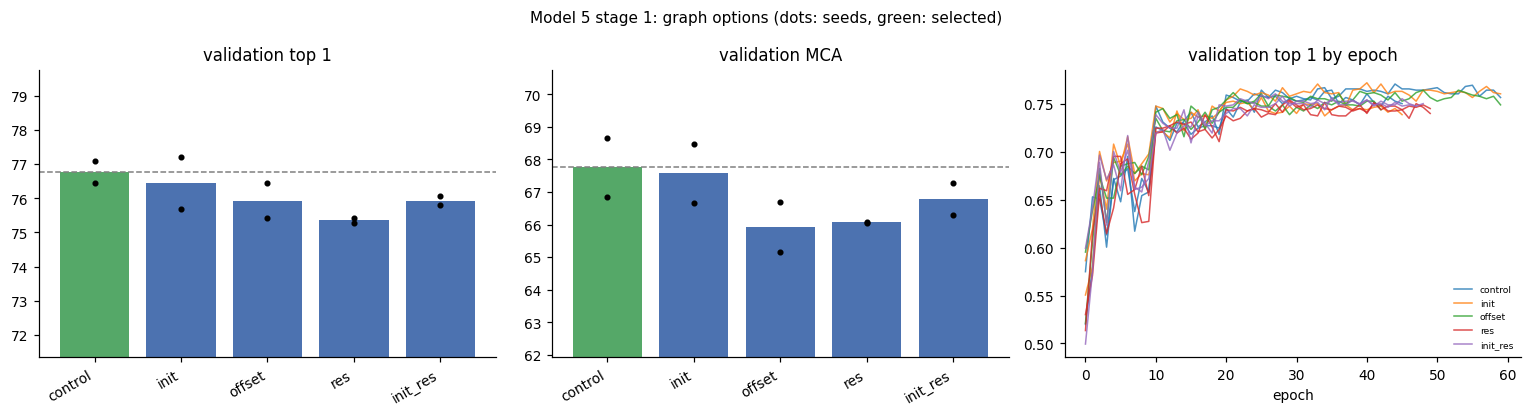

In [7]:
task = Task.init(project_name=PROJECT, task_name="stage1_selection", task_type=Task.TaskTypes.qc,
                 tags=["model5", "stage1", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({**RECIPE, "arms": ARMS, "seeds": SEEDS, "velocity_scale": VEL_SCALE,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP, "tie": TIE}})
slog.report_table("stage 1 comparison (validation, mean over tuning seeds)", "val", iteration=0,
                  table_plot=show.reset_index().rename(columns={"index": "arm"}))
slog.report_single_value("selected_val_top1", float(table.loc[selected, "val top1"]))
slog.report_single_value("control_val_top1", float(base["val top1"]))

order = list(ARMS)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
x = np.arange(len(order))
for ax, metric, title in zip(axes[:2], ["val_top1", "val_mca"], ["validation top 1", "validation MCA"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in order]
    colours = ["#55a868" if n == selected else "#b0b0b0" if n == "control" else "#4c72b0" for n in order]
    ax.bar(x, 100 * np.array(means), color=colours)
    for i, n in enumerate(order):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.axhline(100 * results.loc[results["config"] == "control", metric].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, order, rotation=30, ha="right")
    ax.set_ylim(100 * min(means) - 4, 100 * max(means) + 3)
    ax.set_title(title)
for n, colour in zip(order, plt.cm.tab10.colors):
    for i, s in enumerate(SEEDS):
        c = pd.read_csv(f"{OUT}/model5s1_{n}_s{s}/model5s1_{n}_s{s}_history.csv")
        axes[2].plot(c["epoch"], c["val_top1"], color=colour, lw=1, alpha=0.8, label=n if i == 0 else None)
axes[2].set_title("validation top 1 by epoch")
axes[2].set_xlabel("epoch")
axes[2].legend(frameon=False, fontsize=6)
fig.suptitle("Model 5 stage 1: graph options (dots: seeds, green: selected)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("stage 1 comparison", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

In [8]:
stage = {"stage": 1, "selected": selected, "backbone_options": ARMS[selected], "input": "body_court_velocity",
         "velocity_scale": VEL_SCALE, "tuning": {"seeds": SEEDS, "val_top1": round(float(table.loc[selected, "val top1"]), 4),
                                                  "control_val_top1": round(float(base["val top1"]), 4)}}
os.makedirs(f"{REPO}/configs", exist_ok=True)
with open(f"{REPO}/configs/model5_stage1.json", "w") as f:
    json.dump(stage, f, indent=2)
task.upload_artifact("selected_backbone", artifact_object=f"{REPO}/configs/model5_stage1.json")
task.upload_artifact("results", artifact_object=results_path)
task.close()
stage

{'stage': 1,
 'selected': 'control',
 'backbone_options': {},
 'input': 'body_court_velocity',
 'velocity_scale': 28.841716766357422,
 'tuning': {'seeds': [77, 88], 'val_top1': 0.7676, 'control_val_top1': 0.7676}}

## Reading the result

- If an arm passes, it becomes the backbone for stage 2. Treat a pass as "carry forward", since two seeds cannot
  separate differences under about a point; the final leave one component out ablation on five reporting seeds
  is what decides whether the component stays in the reported model.
- If nothing passes, the learnable graph adds nothing over the default importance weights, which is a result
  worth reporting: on 17 joint skeletons the fixed COCO graph is already close to what the network needs.
- Compare `seconds per epoch` and `parameters` across arms. A gain that costs a lot of compute is weaker evidence
  for a component than the same gain for free.